In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [25]:
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [26]:
df_jan = pd.read_csv('2020-Jan.csv')
df_feb = pd.read_csv('2020-Feb.csv')
#datasetleri birlesdiririk
df = pd.concat([df_jan, df_feb], ignore_index=True)

In [27]:
#tarix sütununu datetime formatına çeviririk və ay sütunu əlavə edirik
df['event_time'] = pd.to_datetime(df['event_time'])
df['month'] = df['event_time'].dt.strftime('%Y-%b')

In [28]:
print(f"Ümumi sətir sayı: {len(df):,}")
df.head()

Ümumi sətir sayı: 8,421,434


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session,month
0,2020-01-01 00:00:00+00:00,view,5809910,1602943681873052386,NaN,grattol,5.24,595414620,4adb70bb-edbd-4981-b60f-a05bfd32683a,2020-Jan
1,2020-01-01 00:00:09+00:00,view,5812943,1487580012121948301,NaN,kinetics,3.97,595414640,c8c5205d-be43-4f1d-aa56-4828b8151c8a,2020-Jan
2,2020-01-01 00:00:19+00:00,view,5798924,1783999068867920626,NaN,zinger,3.97,595412617,46a5010f-bd69-4fbe-a00d-bb17aa7b46f3,2020-Jan
3,2020-01-01 00:00:24+00:00,view,5793052,1487580005754995573,NaN,NaN,4.92,420652863,546f6af3-a517-4752-a98b-80c4c5860711,2020-Jan
4,2020-01-01 00:00:25+00:00,view,5899926,2115334439910245200,NaN,NaN,3.92,484071203,cff70ddf-529e-4b0c-a4fc-f43a749c0acb,2020-Jan


In [29]:
# value counts event type sutunundaki herbir hereketin umumi sayini hesablayir
event_counts = df['event_type'].value_counts()
#normalize true həmin sayları faizə çevirir
event_pct = df['event_type'].value_counts(normalize=True) * 100

event_df = pd.DataFrame({'Count': event_counts, 'Percentage (%)': event_pct.round(2)})
print(event_df)

                    Count  Percentage (%)
event_type                               
view              3991194           47.39
cart              2297017           27.28
remove_from_cart  1627433           19.32
purchase           505790            6.01


In [30]:
# Unique user id-lərin tapılması
view_users = df[df['event_type'] == 'view']['user_id'].nunique() #en azi 1 defe mehsula baxanlarin sayi
cart_users = df[df['event_type'] == 'cart']['user_id'].nunique() #sebete mehsul atanlar
purchase_users = df[df['event_type'] == 'purchase']['user_id'].nunique() #alis eden sexsler

In [31]:
# Conversion Rate-lərin hesablanması
# Mərhələlər arası itkiləri tapırıq
view_to_cart = (cart_users / view_users) * 100 #baxanlarin nece faizi sebete atdi
cart_to_purchase = (purchase_users / cart_users) * 100 #sebete atanlarin nece faizi aldi
overall_conversion = (purchase_users / view_users) * 100
print(f"View Users: {view_users:,}")
print(f"Cart Users: {cart_users:,}")
print(f"Purchase Users: {purchase_users:,}")
print("--- Conversion Rates ---")
print(f"View -> Cart Rate: {view_to_cart:.2f}%")
print(f"Cart -> Purchase Rate: {cart_to_purchase:.2f}%")
print(f"Overall (View -> Purchase) Rate: {overall_conversion:.2f}%")

View Users: 716,987
Cart Users: 162,035
Purchase Users: 49,473
--- Conversion Rates ---
View -> Cart Rate: 22.60%
Cart -> Purchase Rate: 30.53%
Overall (View -> Purchase) Rate: 6.90%


In [32]:
df['main_category'] = df['category_code'].apply(lambda x: x.split('.')[0] if pd.notnull(x) else 'unknown')
#ən çox baxış alan top 8 kateqoriyanın hər biri üçün ayrı-ayrılıqda unikal istifadəçi saylarını və conversion faizlərini hesablayıb yeni cədvələ yığırıq.
top_8_categories = df[df['main_category'] != 'unknown']['main_category'].value_counts().head(8).index

cat_funnel = []
for cat in top_8_categories:
    cat_df = df[df['main_category'] == cat]
    v_u = cat_df[cat_df['event_type'] == 'view']['user_id'].nunique()
    c_u = cat_df[cat_df['event_type'] == 'cart']['user_id'].nunique()
    p_u = cat_df[cat_df['event_type'] == 'purchase']['user_id'].nunique()

    cat_funnel.append({
        'Category': cat,
        'View Users': v_u,
        'Cart Users': c_u,
        'Purchase Users': p_u,
        'View->Cart (%)': round((c_u / v_u) * 100, 2) if v_u > 0 else 0,
        'Cart->Purchase (%)': round((p_u / c_u) * 100, 2) if c_u > 0 else 0,
        'Overall Conversion (%)': round((p_u / v_u) * 100, 2) if v_u > 0 else 0
    })

cat_funnel_df = pd.DataFrame(cat_funnel).sort_values(by='Overall Conversion (%)', ascending=False)
print(cat_funnel_df)

      Category  View Users  Cart Users  Purchase Users  View->Cart (%)  \
1      apparel        4965        4128            1932           83.14   
2   stationery        4313        2265            1025           52.52   
0   appliances       17894        4161            1438           23.25   
3    furniture        8561        1820             487           21.26   
4  accessories        3777         310              93            8.21   
5        sport           2           0               0            0.00   

   Cart->Purchase (%)  Overall Conversion (%)  
1               46.80                   38.91  
2               45.25                   23.77  
0               34.56                    8.04  
3               26.76                    5.69  
4               30.00                    2.46  
5                0.00                    0.00  


In [33]:
#melumatlari aylara gore ayiririq
monthly_metrics = []
for m in ['2020-Jan', '2020-Feb']:
    m_df = df[df['month'] == m]
    v_u = m_df[m_df['event_type'] == 'view']['user_id'].nunique()
    c_u = m_df[m_df['event_type'] == 'cart']['user_id'].nunique()
    p_u = m_df[m_df['event_type'] == 'purchase']['user_id'].nunique()

    monthly_metrics.append({
        'Month': m,
        'View Users': v_u,
        'Cart Users': c_u,
        'Purchase Users': p_u,
        'Overall Conversion (%)': round((p_u / v_u) * 100, 2)
    })

monthly_df = pd.DataFrame(monthly_metrics)
print(monthly_df)
# Hər ay üçün ayrı-ayrılıqda ümumi dönüşüm faizini hesablayıb bir-biri ilə müqayisə edirik
jan_conv = monthly_df[monthly_df['Month'] == '2020-Jan']['Overall Conversion (%)'].values[0]
feb_conv = monthly_df[monthly_df['Month'] == '2020-Feb']['Overall Conversion (%)'].values[0]
diff_pp = feb_conv - jan_conv

print(f"\nFevral ayında Conversion Rate Yanvar ilə müqayisədə {diff_pp:.2f} percentage points (pp) dəyişib.")

      Month  View Users  Cart Users  Purchase Users  Overall Conversion (%)
0  2020-Jan      397775       92653           28220                    7.09
1  2020-Feb      379246       89269           25759                    6.79

Fevral ayında Conversion Rate Yanvar ilə müqayisədə -0.30 percentage points (pp) dəyişib.


In [34]:
# Ən çox alış edilən (purchase) top 10 brendi tapırıq və onların hər biri üzrə baxış-alış nisbətini (conversion rate) hesablayırıq.
brand_metrics = []
for b in top_10_brands:
    b_df = df[df['brand'] == b]
    v_u = b_df[b_df['event_type'] == 'view']['user_id'].nunique()
    p_u = b_df[b_df['event_type'] == 'purchase']['user_id'].nunique()

    brand_metrics.append({
        'Brand': b,
        'Purchases Count': len(b_df[b_df['event_type'] == 'purchase']),
        'View Users': v_u,
        'Purchase Users': p_u,
        'Conversion Rate (%)': round((p_u / v_u) * 100, 2) if v_u > 0 else 0
    })

brand_df = pd.DataFrame(brand_metrics).sort_values(by='Purchases Count', ascending=False)
print(brand_df)

       Brand  Purchases Count  View Users  Purchase Users  Conversion Rate (%)
0     runail            45274       86823           15562                17.92
1      irisk            31210       70510           13332                18.91
2    grattol            21320       48870            7905                16.18
3     masura            19929       35640            5401                15.15
4   ingarden            10276       23716            4972                20.96
5      estel             8616       40234            3994                 9.93
6  bpw.style             8437       13376            3070                22.95
7        uno             6871       22313            4128                18.50
8    italwax             6740       19923            2927                14.69
9     kapous             6370       42289            3018                 7.14


In [36]:
purchases = df[df['event_type'] == 'purchase']['price']
#QR - Interquartile Range məlumatlardakı həddindən artıq ucuz və ya həddindən artıq bahalı məhsulları təmizləmək/aşkar etmək üçün istifadə olunan
Q1 = purchases.quantile(0.25)
Q3 = purchases.quantile(0.75)
IQR = Q3 - Q1
# Q1 (25%-li hədd) və Q3 (75%-li hədd) hesablanır. upper_bound qiymətindən yuxarıda olan məhsullar outlier hesab olunur.
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = purchases[(purchases < lower_bound) | (purchases > upper_bound)]

print(f"Q1: {Q1:.2f}$, Q3: {Q3:.2f}$, IQR: {IQR:.2f}$")
print(f"Upper Bound (Kənar həd): {upper_bound:.2f}$")
print(f"Cəmi Purchase Outlier Sayı: {len(outliers):,} ({len(outliers)/len(purchases)*100:.2f}%)")
print(f"Maksimum Qiymət: {purchases.max()}$")

Q1: 1.59$, Q3: 5.56$, IQR: 3.97$
Upper Bound (Kənar həd): 11.52$
Cəmi Purchase Outlier Sayı: 34,947 (6.91%)
Maksimum Qiymət: 327.78$


In [37]:
# Bonus 1: View-dan Purchase-dək keçən ortalama vaxt
views_df = df[df['event_type'] == 'view'].groupby(['user_id', 'product_id'])['event_time'].min().reset_index()
purchased_df = df[df['event_type'] == 'purchase'].groupby(['user_id', 'product_id'])['event_time'].min().reset_index()

# İstifadəçinin məhsula ilk baxdığı vaxt ilə həmin məhsulu aldığı vaxt arasındakı fərqi saatla hesablayır və orta göstəricini tapır
time_df = pd.merge(views_df, purchased_df, on=['user_id', 'product_id'], suffixes=('_view', '_purchase'))
time_df['time_to_buy_hours'] = (time_df['event_time_purchase'] - time_df['event_time_view']).dt.total_seconds() / 3600

valid_time = time_df[time_df['time_to_buy_hours'] >= 0]
print(f"Ortalama Satınalma Vaxtı: {valid_time['time_to_buy_hours'].mean():.2f} saat")
#Bonus 2: Çox baxılan, lakin demək olar ki, heç alınmayan məhsulları tapır. Bu məhsulun səhifəsində problem olduğunu göstərən metoddur
prod_stats = df.groupby('product_id').agg(
    views=('event_type', lambda x: (x == 'view').sum()),
    purchases=('event_type', lambda x: (x == 'purchase').sum())
).reset_index()

prod_stats = prod_stats[prod_stats['views'] > 1000]
prod_stats['conversion_rate'] = (prod_stats['purchases'] / prod_stats['views']) * 100
high_view_low_conv = prod_stats.sort_values(by='conversion_rate', ascending=True).head(5)

print("\n--- High View, Low Conversion Products ---")
print(high_view_low_conv)

Ortalama Satınalma Vaxtı: 54.07 saat

--- High View, Low Conversion Products ---
       product_id  views  purchases  conversion_rate
1270        27759   1062          0         0.000000
46864     5915337   5900          5         0.084746
6868      5688835   1135          1         0.088106
19046     5808664  17194         23         0.133768
18686     5805511   1302          2         0.153610


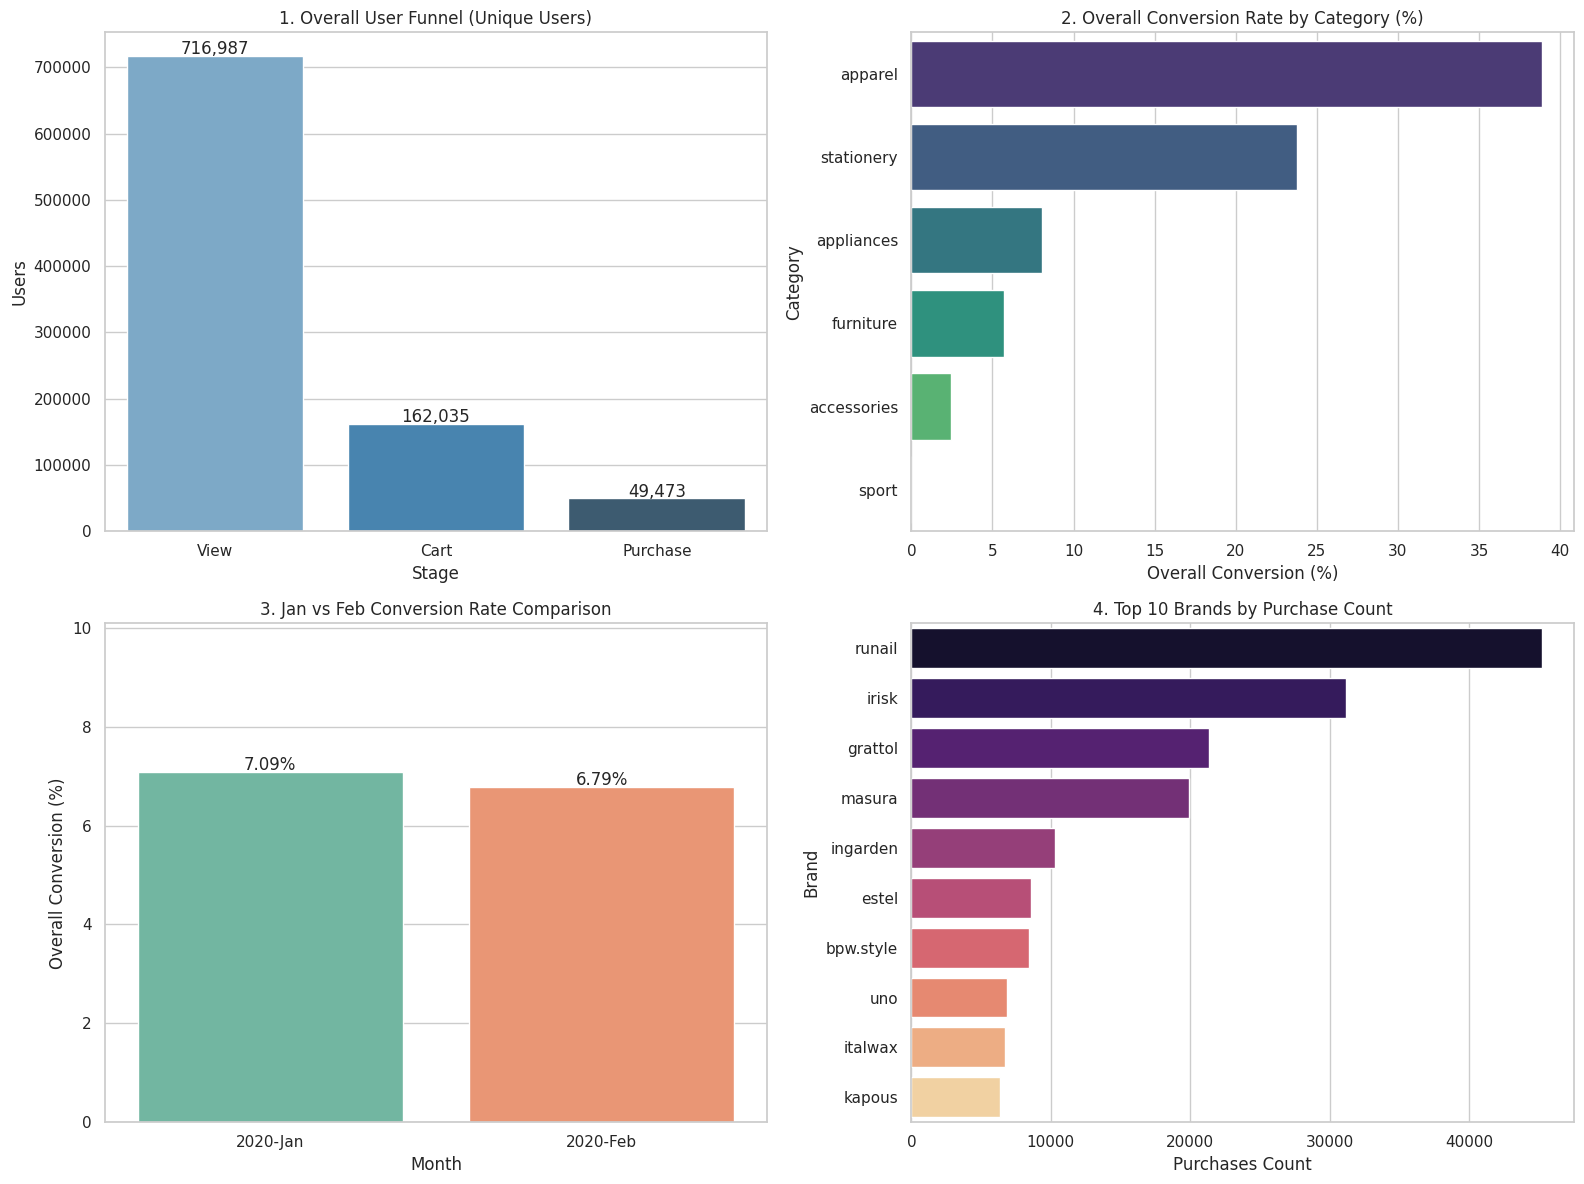

In [41]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Funnel Bar Chart
funnel_data = pd.DataFrame({'Stage': ['View', 'Cart', 'Purchase'], 'Users': [view_users, cart_users, purchase_users]})
sns.barplot(ax=axes[0,0], data=funnel_data, x='Stage', y='Users', hue='Stage', palette='Blues_d', legend=False)
axes[0,0].set_title('1. Overall User Funnel (Unique Users)')
for p in axes[0,0].patches:
    axes[0,0].annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                       ha='center', va='center', xytext=(0, 5), textcoords='offset points')

# 2. Conversion Rate by Category
sns.barplot(ax=axes[0,1], data=cat_funnel_df, x='Overall Conversion (%)', y='Category', hue='Category', palette='viridis', legend=False)
axes[0,1].set_title('2. Overall Conversion Rate by Category (%)')

# 3. Jan vs Feb Comparison
sns.barplot(ax=axes[1,0], data=monthly_df, x='Month', y='Overall Conversion (%)', hue='Month', palette='Set2', legend=False)
axes[1,0].set_title('3. Jan vs Feb Conversion Rate Comparison')
axes[1,0].set_ylim(0, max(monthly_df['Overall Conversion (%)']) + 3)
for p in axes[1,0].patches:
    axes[1,0].annotate(f'{p.get_height():.2f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                       ha='center', va='center', xytext=(0, 5), textcoords='offset points')

# 4. Top 10 Brands by Purchase Count
sns.barplot(ax=axes[1,1], data=brand_df, x='Purchases Count', y='Brand', hue='Brand', palette='magma', legend=False)
axes[1,1].set_title('4. Top 10 Brands by Purchase Count')

plt.tight_layout()
plt.show()